In [2]:
#IMPORT STATEMENTS (CHATGPT)
import pandas as pd
df = pd.read_excel(
    "Lab Session Data (2).xlsx",
    sheet_name="marketing_campaign")
print(df.head())

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

           Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
0  2012-04-09 00:00:00       58       635  ...                  7   
1  2014-08-03 00:00:00       38        11  ...                  5   
2           21-08-2013       26       426  ...                  4   
3  2014-10-02 00:00:00       26        11  ...                  6   
4           19-01-2014       94       173  ...                  5   

   AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  \
0             0             0            

In [41]:
#a2 labelencoding - AI (CHATGPT)

from sklearn.preprocessing import LabelEncoder
def label_encode(data, columns):
    data = data.copy()
    encoder = LabelEncoder()
    for col in columns:
        data[col] = encoder.fit_transform(data[col])
    return data

cat_cols = ["Education", "Marital_Status"]
label_data = label_encode(df, cat_cols)
print(label_data.head())



#a2 onehotencoding - AI (CHATGPT)

import pandas as pd
def one_hot_encode(data, columns):
    return pd.get_dummies(data, columns=columns)

cat_cols = ["Education", "Marital_Status"]
onehot_data = one_hot_encode(df, cat_cols)
print(onehot_data.head())





#OWN CODE



     ID  Year_Birth  Education  Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957          2               4  58138.0        0         0   
1  2174        1954          2               4  46344.0        1         1   
2  4141        1965          2               5  71613.0        0         0   
3  6182        1984          2               5  26646.0        1         0   
4  5324        1981          4               3  58293.0        1         0   

           Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
0  2012-04-09 00:00:00       58       635  ...                  7   
1  2014-08-03 00:00:00       38        11  ...                  5   
2           21-08-2013       26       426  ...                  4   
3  2014-10-02 00:00:00       26        11  ...                  6   
4           19-01-2014       94       173  ...                  5   

   AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  \
0             0             0            

In [44]:
#A3 - AI (CHATGPT)

def dataset_shape(data):
    return data.shape
cat_cols = ["Education", "Marital_Status"]
label_data = label_encode(df, cat_cols)
onehot_data = one_hot_encode(df, cat_cols)
print("Original :", dataset_shape(df))
print("Label :", dataset_shape(label_data))
print("One Hot :", dataset_shape(onehot_data))

#OWN CODE



Original : (2240, 29)
Label : (2240, 29)
One Hot : (2240, 40)


In [21]:
#a4 - AI (CHATGPT)

import numpy as np
def minkowski_distance(a, b, p):
    a = np.array(a)
    b = np.array(b)
    return (np.sum(np.abs(a - b) ** p)) ** (1 / p)

numeric_data = df.select_dtypes(include="number").dropna()
v1 = numeric_data.iloc[0].values
v2 = numeric_data.iloc[1].values
d = minkowski_distance(v1, v2, 2)
print("Distance =", d)



#OWN CODE
def minkowski_distance(vector1, vector2, p):
    vector1 = np.array(vector1, dtype=float)
    vector2 = np.array(vector2, dtype=float)
    distance_value = np.sum(np.abs(vector1 - vector2) ** p) ** (1 / p)
    return distance_value

print("Test distance (p=1):", minkowski_distance([1, 2], [4, 6], 1))
print("Test distance (p=2):", minkowski_distance([1, 2], [4, 6], 2))

Distance = 12290.371231171172
Test distance (p=1): 7.0
Test distance (p=2): 5.0


In [6]:
#a5 - AI (CHATGPT)

import matplotlib.pyplot as plt
def distance_values(a, b):
    values = []
    for p in range(1,11):
        values.append(minkowski_distance(a,b,p))
    return values

dist = distance_values(v1,v2)
plt.plot(range(1,11),dist,marker='o')
plt.xlabel("p")
plt.ylabel("Distance")
plt.show()



#OWN CODE


Distance = 12290.371231171172


In [30]:
#a6 - AI (CHATGPT)

from scipy.spatial.distance import minkowski
def compare_distance(a,b,p):
    own = minkowski_distance(a,b,p)
    scipy = minkowski(a,b,p)
    return own, scipy

x,y = compare_distance(v1,v2,2)
print("Own :",x)
print("Scipy :",y)



#OWN CODE

scipy_distances = [minkowski(v1, v2, p) for p in p_values]
comparison_df = pd.DataFrame({
    'p': p_values,
    'Own Function': own_distances,
    'Scipy Function': scipy_distances
})
print(comparison_df)

Own : 12290.371231171172
Scipy : 12290.371231171172
   p  Own Function  Scipy Function
0  1  16781.000000    16781.000000
1  2  12290.371231    12290.371231
2  3  11884.374554    11884.374554
3  4  11813.182057    11813.182057
4  5  11798.359466    11798.359466


In [33]:
#a7 - AI (CHATGPT)

import numpy as np
def dot_product(a, b):
    return np.sum(a * b)
def vector_norm(a):
    return np.sqrt(np.sum(a ** 2))

num = df.select_dtypes(include="number").dropna().to_numpy()
v1 = num[0]
v2 = num[1]
print("Our Dot :", dot_product(v1, v2))
print("NumPy Dot :", np.dot(v1, v2))
print("Our Norm v1 :", vector_norm(v1))
print("NumPy Norm v1 :", np.linalg.norm(v1))
print("Our Norm v2 :", vector_norm(v2))
print("NumPy Norm v2 :", np.linalg.norm(v2))


#OWN CODE

def dot_product(vector1, vector2):
    vector1 = np.array(vector1, dtype=float)
    vector2 = np.array(vector2, dtype=float)
    return np.sum(vector1 * vector2)

def euclidean_norm(vector):
    vector = np.array(vector, dtype=float)
    return np.sqrt(np.sum(vector ** 2))

own_dot = dot_product(v1, v2)
own_norm_A = euclidean_norm(v1)

numpy_dot = np.dot(v1.astype(float), v2.astype(float))
numpy_norm_A = np.linalg.norm(v1.astype(float))

print("Own dot product:", own_dot, "| Numpy dot product:", numpy_dot)
print("Own norm of A:", own_norm_A, "| Numpy norm of A:", numpy_norm_A)

Our Dot : 2710194336.0
NumPy Dot : 2710194336.0
Our Norm v1 : 58439.10812974476
NumPy Norm v1 : 58439.10812974476
Our Norm v2 : 46436.11243418208
NumPy Norm v2 : 46436.11243418208
Own dot product: 2710194336.0 | Numpy dot product: 2710194336.0
Own norm of A: 58439.10812974476 | Numpy norm of A: 58439.10812974476


In [38]:
#a8 - AI (CHATGPT)

import numpy as np
def statistics(data):
    mean = np.sum(data) / len(data)
    variance = np.sum((data - mean) ** 2) / len(data)
    std = np.sqrt(variance)
    return mean, variance, std

feature = df["Income"].dropna().to_numpy()
mean, var, std = statistics(feature)
print("Mean :", mean)
print("Variance :", var)
print("Standard Deviation :", std)



#OWN CODE

def calculate_mean(data_matrix):
    n = data_matrix.shape[0]
    mean = np.sum(data_matrix, axis=0) / n
    return mean

def calculate_variance(data_matrix):
    n = data_matrix.shape[0]
    mean = calculate_mean(data_matrix)
    variance = np.sum((data_matrix - mean) ** 2, axis=0) / n
    return variance

def calculate_std(data_matrix):
    variance = calculate_variance(data_matrix)
    return np.sqrt(variance)

feature_matrix = df["Income"].dropna().values
own_mean = calculate_mean(feature_matrix)
own_variance = calculate_variance(feature_matrix)
own_std = calculate_std(feature_matrix)
print("Mean :", own_mean)
print("Variance :", own_variance)
print("Standard Deviation :", own_std)


Mean : 52247.25135379061
Variance : 633397830.1872725
Standard Deviation : 25167.396174162965
Mean : 52247.25135379061
Variance : 633397830.1872725
Standard Deviation : 25167.396174162965


In [40]:
#a9 - AI (CHATGPT)

mean, var, std = statistics(feature)
print("Mean :", mean)
print("NumPyMean :", np.mean(feature))

print("Std :", std)
print("NumPy Std :", np.std(feature))


#OWN CODE

numpy_mean = feature_matrix.mean(axis=0)
numpy_std = feature_matrix.std(axis=0)
print("Numpy mean:", numpy_mean)
print("Numpy std:", numpy_std)
print("Max diff (mean):", np.abs(own_mean - numpy_mean).max())
print("Max diff (std):", np.abs(own_std - numpy_std).max())

Mean : 52247.25135379061
NumPyMean : 52247.25135379061
Std : 25167.396174162965
NumPy Std : 25167.396174162965
Numpy mean: 52247.25135379061
Numpy std: 25167.396174162965
Max diff (mean): 0.0
Max diff (std): 0.0


Mean : 52247.25135379061
NumPyMean : 52247.25135379061
Std : 25167.396174162965
NumPy Std : 25167.396174162965


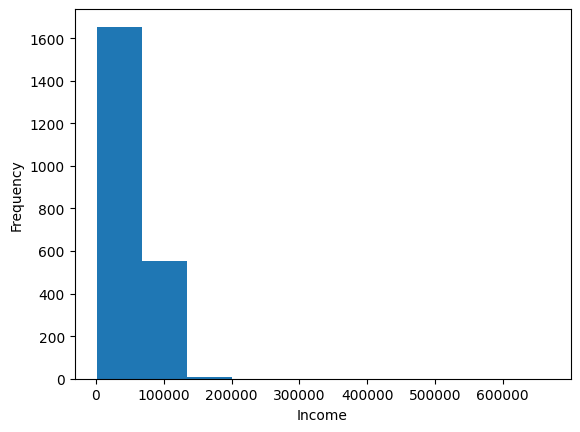

Mean : 52247.25135379061
Variance : 633397830.1872725


In [12]:
#a10 - AI (CHATGPT)

import matplotlib.pyplot as plt
def histogram(feature, bins):
    plt.hist(feature, bins=bins)
    plt.xlabel("Income")
    plt.ylabel("Frequency")
    plt.show()

histogram(feature, 10)
mean, var, std = statistics(feature)
print("Mean :", mean)
print("Variance :", var)

In [47]:
#a11 - AI (CHATGPT)

import numpy as np
def kmeans(data, k, iterations):
    centroids = data[:k]
    for _ in range(iterations):
        distance = np.linalg.norm(data[:, None] - centroids, axis=2)
        labels = np.argmin(distance, axis=1)
        new_centroids = np.array([
            data[labels == i].mean(axis=0)
            for i in range(k)])
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    return labels, centroids

X = df[["Income", "MntWines"]].dropna().to_numpy()
labels, centroids = kmeans(X, 3, 100)
print("Labels")
print(labels)
print("Centroids")
print(centroids)






Labels
[0 0 2 ... 0 2 0]
Centroids
[[5.56852568e+04 3.47049383e+02]
 [2.98794719e+04 3.90107527e+01]
 [8.02561213e+04 6.36768014e+02]]


....

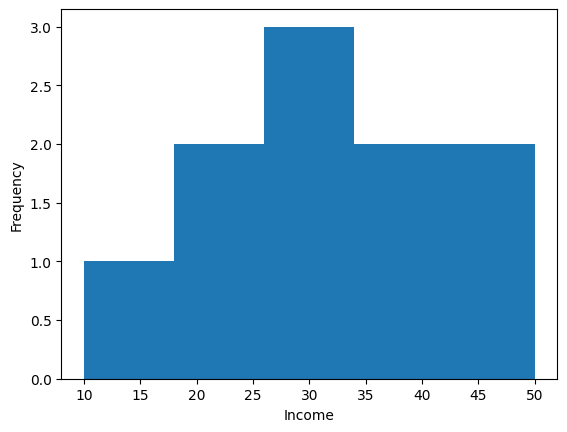

.................
----------------------------------------------------------------------
Ran 21 tests in 0.203s

OK


In [50]:
# A2 - UNIT TESTING
# GenAI Tool: ChatGPT

import unittest
import numpy as np
import pandas as pd
from scipy.spatial.distance import minkowski


class TestLab03Functions(unittest.TestCase):


# A2 - LABEL ENCODING
    def test_label_encoding(self):

        test_df = pd.DataFrame({
            "Education": ["Graduation", "PhD", "Graduation"],
            "Income": [50000, 60000, 55000]
        })

        result = label_encode(test_df, ["Education"])

        # Number of unique categories should remain 2
        self.assertEqual(
            result["Education"].nunique(),
            2
        )

        # Number of rows and columns should remain unchanged
        self.assertEqual(
            result.shape,
            test_df.shape
        )


# A2 - ONE-HOT ENCODING
    def test_one_hot_encoding(self):

        test_df = pd.DataFrame({
            "Education": ["Graduation", "PhD", "Graduation"],
            "Income": [50000, 60000, 55000]
        })

        result = one_hot_encode(
            test_df,
            ["Education"]
        )

        # Check whether encoded columns were created
        self.assertIn(
            "Education_Graduation",
            result.columns
        )

        self.assertIn(
            "Education_PhD",
            result.columns
        )

        # Number of rows must remain the same
        self.assertEqual(
            len(result),
            len(test_df)
        )


# A3 - DATASET DIMENSIONALITY
    def test_dataset_shape(self):

        test_df = pd.DataFrame({
            "A": [1, 2, 3],
            "B": [4, 5, 6]
        })

        result = dataset_shape(test_df)

        self.assertEqual(
            result,
            (3, 2)
        )



# A4 - MINKOWSKI DISTANCE
    def test_minkowski_distance(self):

        a = np.array([1, 2])
        b = np.array([4, 6])

        # p = 1 → Manhattan distance
        result_p1 = minkowski_distance(a, b, 1)

        self.assertAlmostEqual(
            result_p1,
            7.0
        )

        # p = 2 → Euclidean distance
        result_p2 = minkowski_distance(a, b, 2)

        self.assertAlmostEqual(
            result_p2,
            5.0
        )



  # A5 - MINKOWSKI DISTANCE FOR p = 1 TO 10
    def test_distance_values(self):

        a = np.array([1, 2])
        b = np.array([4, 6])

        result = distance_values(a, b)

        # There should be 10 distance values
        self.assertEqual(
            len(result),
            10
        )

        # First value corresponds to p = 1
        self.assertAlmostEqual(
            result[0],
            7.0
        )



# A6 - OWN MINKOWSKI VS SCIPY
    def test_scipy_comparison(self):

        a = np.array([1, 2])
        b = np.array([4, 6])

        for p in range(1, 11):

            own_result = minkowski_distance(
                a,
                b,
                p
            )

            scipy_result = minkowski(
                a,
                b,
                p
            )

            # Both implementations should give same result
            self.assertAlmostEqual(
                own_result,
                scipy_result
            )



# A7 - DOT PRODUCT AND EUCLIDEAN NORM
    def test_dot_product(self):

        a = np.array([1, 2, 3])
        b = np.array([4, 5, 6])

        expected = 32

        self.assertEqual(
            dot_product(a, b),
            expected
        )


    def test_euclidean_norm(self):

        a = np.array([3, 4])

        expected = 5.0

        self.assertAlmostEqual(
            euclidean_norm(a),
            expected
        )



# A8 - MEAN, VARIANCE AND STANDARD DEVIATION
    def test_statistics(self):

        data = np.array([1, 2, 3, 4, 5])

        mean, variance, std = statistics(data)

        self.assertAlmostEqual(
            mean,
            3.0
        )

        self.assertAlmostEqual(
            variance,
            2.0
        )

        self.assertAlmostEqual(
            std,
            np.sqrt(2)
        )


# A9 - COMPARE WITH NUMPY
    def test_statistics_with_numpy(self):

        data = np.array([1, 2, 3, 4, 5])

        mean, variance, std = statistics(data)

        # Compare mean
        self.assertAlmostEqual(
            mean,
            np.mean(data)
        )

        # Compare standard deviation
        self.assertAlmostEqual(
            std,
            np.std(data)
        )



# A10 - HISTOGRAM
    def test_histogram(self):

        data = np.array([
            10, 20, 20, 30, 30,
            30, 40, 40, 50, 50
        ])

        # Check that histogram function executes
        # without producing an error
        try:
            histogram(data, 5)
            result = True
        except Exception:
            result = False

        self.assertTrue(result)

        # Check statistical values used in A10
        mean, variance, std = statistics(data)

        self.assertAlmostEqual(
            mean,
            32.0
        )



 # A11 - K-MEANS
    def test_kmeans(self):

        test_data = np.array([
            [1, 1],
            [1, 2],
            [2, 1],
            [8, 8],
            [9, 8],
            [8, 9]
        ], dtype=float)

        labels, centroids = kmeans(
            test_data,
            2,
            100
        )

        # There must be exactly 2 clusters
        self.assertEqual(
            len(np.unique(labels)),
            2
        )

        # There must be 2 centroids
        # and each centroid has 2 features
        self.assertEqual(
            centroids.shape,
            (2, 2)
        )

unittest.main(
    argv=[''],
    exit=False
)